# Imputation DiD

With staggered adoption, a two-way fixed effects regression can use already-treated
units as controls and return a biased estimate. The imputation estimator of Borusyak,
Jaravel & Spiess (2024) avoids that by construction, and asks a simple question
instead: **what would each treated observation have looked like without treatment, and
how far is the observed outcome from that?**

**What you'll learn**

- How the estimator imputes untreated outcomes, and what it assumes to do so
- How to fit it and read the overall effect, the event study and cohort effects
- How to look at pre-treatment evidence, and what the joint pre-trend test does
- How it compares with Callaway-Sant'Anna and Sun-Abraham, and when it is more precise
- What `anticipation` and `aux_partition` change

**Prerequisites:** [Staggered DiD](02_staggered_did.ipynb).

In [1]:
import numpy as np
import pandas as pd

from diff_diff import (
    CallawaySantAnna,
    ImputationDiD,
    SunAbraham,
    generate_staggered_data,
    plot_event_study,
)

## What it estimates and assumes

The estimator works in three steps:

1. Fit unit and period fixed effects on the **untreated observations only**: the
   never-treated units in every period, and the eventually-treated units before their
   treatment starts.
2. For each treated observation, **impute** the untreated outcome from those fixed
   effects, and take the difference from the observed outcome. That difference is an
   estimate of that observation's treatment effect.
3. **Average** the observation-level effects with weights that define the target.

**Target parameter.** With equal weights on every treated observation, the average
treatment effect on the treated (ATT). Other weights give the effect at each horizon
(an event study) or for each cohort; steps 1 and 2 do not change.

**Identifying assumptions.**

- **Parallel trends**, in the form the paper uses: without treatment, every unit's
  expected outcome is a unit effect plus a period effect, for all units and all periods.
  This is stronger than the Callaway-Sant'Anna versions, which restrict trends only
  from the period before treatment onward. It is what lets the estimator use every
  untreated observation, including early pre-treatment periods.
- **No anticipation:** outcomes do not respond before treatment starts.
- Treatment is **absorbing**: once treated, always treated.

Nothing is assumed about the treatment effects themselves. They may differ across
units, cohorts and time, and the estimator remains unbiased.

**What would violate it.** Group-specific trends: if a cohort was already on a different
path several periods before treatment, the fixed effects fitted on its early periods
give the wrong counterfactual. Anticipation contaminates the last pre-treatment
periods, which are used as untreated data.

## Simulated data

A panel of 300 units over 10 periods. Three cohorts start treatment in periods 3, 5 and
7, and 90 units are never treated. The true effect is 2.0 for every treated unit in
every treated period.

In [2]:
TRUE_ATT = 2.0

data = generate_staggered_data(
    n_units=300,
    n_periods=10,
    treatment_effect=TRUE_ATT,
    dynamic_effects=False,  # constant effect: the same in every period after treatment
    seed=42,
)

cohort_sizes = data.groupby("unit")["first_treat"].first().value_counts().sort_index()
print("Units by first treated period (0 = never treated):")
print(cohort_sizes.to_string())
print(f"\nTrue ATT: {TRUE_ATT}")

Units by first treated period (0 = never treated):
first_treat
0    90
3    60
5    75
7    75

True ATT: 2.0


## Fitting the estimator

Standard errors are clustered by unit, which is the default.

In [3]:
estimator = ImputationDiD(pretrends=True)
results = estimator.fit(
    data,
    outcome="outcome",
    unit="unit",
    time="period",
    first_treat="first_treat",
)

print(results.summary())

               Imputation DiD Estimator Results (Borusyak et al. 2024)               

Total observations:                  3000
Treated observations:                1020
Untreated observations:              1980
Treated units:                        210
Control units:                        300
Treatment cohorts:                      3
Time periods:                          10

Variance estimator:            CR1 cluster-robust at unit, G=300
Number of clusters:                        300

-------------------------------------------------------------------------------------
                   Overall Average Treatment Effect on the Treated                   
-------------------------------------------------------------------------------------
Parameter           Estimate    Std. Err.     t-stat      P>|t|   Sig.
-------------------------------------------------------------------------------------
ATT                   1.9817       0.0369     53.727     0.0000    ***
-------------------

In [4]:
print(f"Estimate: {results.att:.3f}  (SE {results.se:.3f})")
print(f"95% CI:   [{results.conf_int[0]:.3f}, {results.conf_int[1]:.3f}]")
print(f"True ATT: {TRUE_ATT:.3f}")

Estimate: 1.982  (SE 0.037)
95% CI:   [1.909, 2.054]
True ATT: 2.000


The estimate is 1.98 with a 95% interval of [1.91, 2.05], which contains the true effect
of 2.0.

Two lines of the summary are worth a note. "Treated observations: 1020" is the number of
unit-periods under treatment, each of which gets an imputed untreated outcome. "Control
units: 300" counts every unit that contributes at least one untreated observation, which
is all of them: the 210 eventually-treated units contribute their pre-treatment periods.

## Event study

`aggregate("event_study")` regroups the same observation-level effects by time since
treatment. Because the estimator was built with `pretrends=True`, the event study also
carries coefficients for the periods before treatment. They come from a separate
regression on the untreated observations, with the period just before treatment
(event time -1) as the reference.

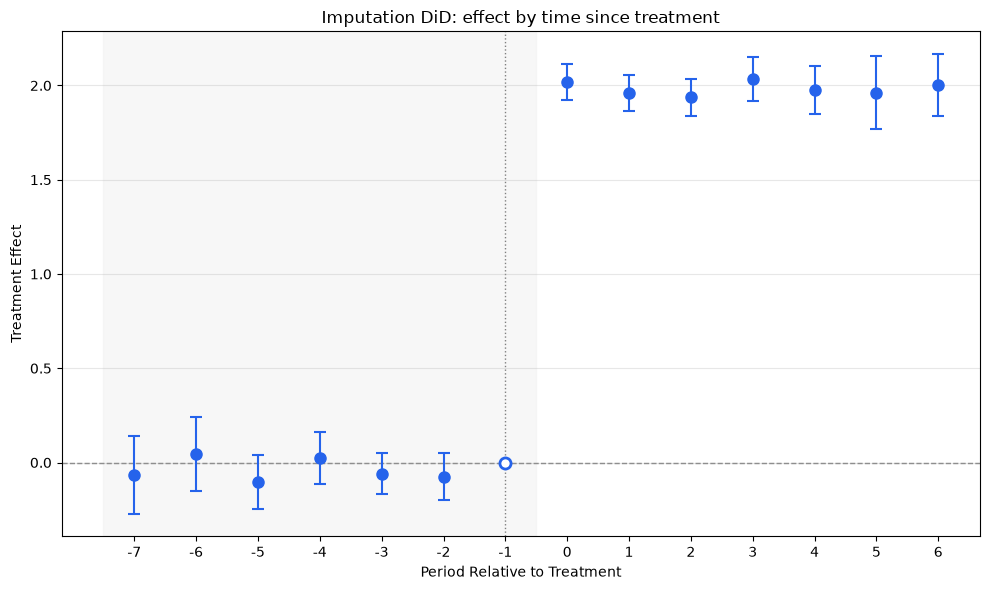

In [5]:
es = results.aggregate("event_study")

ax = plot_event_study(es, title="Imputation DiD: effect by time since treatment", show=False)

In [6]:
columns = ["event_time", "att", "se", "conf_int_lower", "conf_int_upper", "is_reference"]
print(es.to_dataframe()[columns].round(3).to_string(index=False))

 event_time    att    se  conf_int_lower  conf_int_upper  is_reference
         -7 -0.064 0.105          -0.271           0.143         False
         -6  0.045 0.100          -0.151           0.242         False
         -5 -0.102 0.073          -0.245           0.040         False
         -4  0.023 0.071          -0.116           0.162         False
         -3 -0.058 0.055          -0.167           0.050         False
         -2 -0.074 0.062          -0.197           0.048         False
         -1  0.000   NaN             NaN             NaN          True
          0  2.018 0.048           1.924           2.112         False
          1  1.962 0.049           1.866           2.057         False
          2  1.937 0.051           1.838           2.036         False
          3  2.033 0.059           1.918           2.149         False
          4  1.975 0.065           1.848           2.101         False
          5  1.961 0.099           1.768           2.155         False
      

After treatment the estimates sit close to 2.0 at every horizon. Their standard errors
grow with the horizon because fewer cohorts are observed that long after treatment: only
the earliest cohort reaches event time 6.

Before treatment the coefficients are small next to their standard errors; the largest,
at event time -5, is 1.4 standard errors from zero. Read that as the absence of visible
evidence against parallel trends, not as confirmation of it: coefficients can be
individually insignificant while a violation large enough to matter goes undetected.
[Pre-Trends Power](07_pretrends_power.ipynb) shows how to ask what such a check could
have detected, and [Honest DiD Sensitivity](05_honest_did.ipynb) how to report results
that allow for a violation.

### A joint test of the pre-treatment coefficients

`pretrend_test()` tests whether a chosen number of pre-treatment coefficients are jointly
zero. It runs its own regression on the untreated observations, so it does not need
`pretrends=True`.

In [7]:
pretrend = results.pretrend_test(n_leads=3)

print(f"F statistic: {pretrend['f_stat']:.3f}")
print(f"p-value:     {pretrend['p_value']:.3f}")
print(f"Leads tested: {pretrend['n_leads']}")

F statistic: 1.269
p-value:     0.285
Leads tested: 3


The test does not reject (p = 0.285). As with the plot, that is not evidence that
parallel trends holds; it says the three coefficients just before treatment are jointly
compatible with zero at this sample size.

One property is specific to this estimator. When the errors have equal variance and are
uncorrelated across units and periods, the paper shows this test is uncorrelated with the effect
estimate, and independent of it if the errors are also normal (Proposition 9). In that
case conditioning on the test's outcome does not distort the estimate, which is the
problem Roth (2022) identifies for pre-tests in general. Outside that case, treat it like
any other pre-test.

## Effects by cohort

The same fitted object gives an effect per cohort. No refit is needed.

In [8]:
columns = ["label", "att", "se", "conf_int_lower", "conf_int_upper", "n"]
print(results.aggregate("group").to_dataframe()[columns].round(3).to_string(index=False))

label   att    se  conf_int_lower  conf_int_upper     n
    3 2.005 0.050           1.907           2.103 420.0
    5 1.999 0.049           1.903           2.095 375.0
    7 1.908 0.055           1.800           2.017 225.0


All three cohort estimates are close to 2.0 and their intervals contain it, as they
should when the true effect is the same for every cohort.

## Comparison with other estimators

Callaway-Sant'Anna and Sun-Abraham target the same overall effect here. They differ in
which untreated observations they use: by default both compare each cohort with the
never-treated units, from the period before treatment. The imputation estimator uses
every untreated observation.

In [9]:
fit_args = dict(outcome="outcome", unit="unit", time="period", first_treat="first_treat")
fits = {
    "ImputationDiD": results,
    "CallawaySantAnna": CallawaySantAnna().fit(data, **fit_args),
    "SunAbraham": SunAbraham().fit(data, **fit_args),
}

print(f"{'Estimator':<18} {'ATT':>7} {'SE':>8} {'95% CI':>18} {'covers 2.0':>11}")
for name, fit in fits.items():
    lower, upper = fit.conf_int
    print(
        f"{name:<18} {fit.att:>7.3f} {fit.se:>8.4f} {f'[{lower:.3f}, {upper:.3f}]':>18} "
        f"{str(lower <= TRUE_ATT <= upper):>11}"
    )

ratio = fits["ImputationDiD"].se / fits["CallawaySantAnna"].se
print(f"\nImputation SE as a share of the Callaway-Sant'Anna SE: {ratio:.0%}")

Estimator              ATT       SE             95% CI  covers 2.0
ImputationDiD        1.982   0.0369     [1.909, 2.054]        True
CallawaySantAnna     1.975   0.0528     [1.872, 2.079]        True
SunAbraham           1.975   0.0527     [1.872, 2.079]        True

Imputation SE as a share of the Callaway-Sant'Anna SE: 70%


All three intervals contain the true effect. Callaway-Sant'Anna and Sun-Abraham agree
to three decimals because, with never-treated controls and no covariates, they make the
same comparisons ([Staggered DiD](02_staggered_did.ipynb) shows why).

The imputation standard error is 70% of the Callaway-Sant'Anna one, so its interval is
30% shorter. The gain comes from using every untreated observation instead of one
pre-treatment period per comparison, and it has a condition: the paper shows the
imputation estimator has the smallest variance of any linear unbiased estimator when the
errors have equal variance and are uncorrelated across units and periods (Theorem 1),
which is how this simulated noise was generated. The shorter interval is what was
observed here, not part of the theorem: an interval's width also depends on the variance
estimator. It is **not** a condition on the treatment effects: the estimator
is unbiased, and this result holds, whether effects are the same for everyone or not.
With strongly serially correlated errors, early pre-treatment periods say less about the
period just before treatment and the ranking is not guaranteed.

## Options

### Anticipation

`anticipation=k` tells the estimator that outcomes may respond up to `k` periods before
the recorded treatment date. It then treats those periods as treated: they are no longer
used to fit the untreated model, and their effects enter the average.

In [10]:
with_anticipation = ImputationDiD(anticipation=1).fit(data, **fit_args)

print(f"ATT, no anticipation:        {results.att:.3f}")
print(f"ATT, one period anticipated: {with_anticipation.att:.3f}")

ATT, no anticipation:        1.982
ATT, one period anticipated: 1.674


The estimate falls from 1.98 to 1.67, and it is the second number that is wrong here.
The simulated data has no anticipation, so the period before treatment has no effect.
Declaring one period of anticipation reclassifies those 210 unit-periods as treated and
averages their effects, which are zero, in with the 1,020 real ones: roughly
2.0 x 1020 / 1230 = 1.66.

So `anticipation` is not a robustness switch to flip and compare. Set it when you have a
reason to expect a response before the recorded date, such as an announced policy, and
note that it changes the target: the average then covers the anticipation periods too.

### The auxiliary partition for standard errors

The standard errors are conservative: they need an estimate of each treated
observation's effect to form residuals, and `aux_partition` chooses the groups over
which those effects are averaged. The default groups by cohort and horizon.

In [11]:
for partition in ["cohort_horizon", "cohort", "horizon"]:
    fit = ImputationDiD(aux_partition=partition).fit(data, **fit_args)
    print(f"aux_partition={partition!r:<17} ATT = {fit.att:.3f}   SE = {fit.se:.4f}")

aux_partition='cohort_horizon'  ATT = 1.982   SE = 0.0369
aux_partition='cohort'          ATT = 1.982   SE = 0.0369
aux_partition='horizon'         ATT = 1.982   SE = 0.0370


The point estimate does not depend on the partition, and here the standard errors barely
do: on this balanced panel `"cohort"` coincides with the default, and `"horizon"` differs
in the fourth decimal. Coarser partitions average the effects over larger groups and are
usually, though not always, more conservative.

## Summary

- The imputation estimator fits unit and period effects on untreated observations,
  imputes each treated observation's untreated outcome, and averages the differences.
- It is unbiased under parallel trends and no anticipation whatever the pattern of
  treatment effects. It does not need effects to be the same across units or over time.
- It uses every untreated observation, which rests on parallel trends holding in all
  periods, and makes it more precise than estimators that use only the period before
  treatment when errors are independent and equally variable.
- One fit gives the overall effect, the event study and cohort effects.

## When to use it and when not to

Use it for staggered adoption with absorbing treatment when parallel trends is credible
over the whole pre-treatment window, and precision matters. Prefer an estimator that
restricts trends only around the treatment date, such as Callaway-Sant'Anna, when early
pre-treatment periods are suspect; and compare the two, since a gap between them points
at those early periods. It needs untreated observations in every period of interest:
without never-treated units, effects at long horizons are not identified.

## Next steps

- [Two-Stage DiD](12_two_stage_did.ipynb): the same point estimates from a two-stage
  regression, with a different variance estimator
- [Efficient DiD](15_efficient_did.ipynb): efficiency under a different set of
  assumptions
- [Honest DiD Sensitivity](05_honest_did.ipynb): what the conclusion is worth if parallel
  trends fails by a bounded amount

## References

- Borusyak, K., Jaravel, X., & Spiess, J. (2024). "Revisiting Event-Study Designs: Robust
  and Efficient Estimation." *The Review of Economic Studies*, 91(6), 3253-3285.
- Callaway, B., & Sant'Anna, P. H. C. (2021). "Difference-in-Differences with Multiple Time
  Periods." *Journal of Econometrics*, 225(2), 200-230.
- Sun, L., & Abraham, S. (2021). "Estimating Dynamic Treatment Effects in Event Studies
  with Heterogeneous Treatment Effects." *Journal of Econometrics*, 225(2), 175-199.